In [1]:
import pandas as pd
df = pd.read_csv(r"C:\Users\aklis\Downloads\iris\Research\Datasets\PaySim\PS_20174392719_1491204439457_log.csv")
print(df.head())


   step      type    amount     nameOrig  oldbalanceOrg  newbalanceOrig  \
0     1   PAYMENT   9839.64  C1231006815       170136.0       160296.36   
1     1   PAYMENT   1864.28  C1666544295        21249.0        19384.72   
2     1  TRANSFER    181.00  C1305486145          181.0            0.00   
3     1  CASH_OUT    181.00   C840083671          181.0            0.00   
4     1   PAYMENT  11668.14  C2048537720        41554.0        29885.86   

      nameDest  oldbalanceDest  newbalanceDest  isFraud  isFlaggedFraud  
0  M1979787155             0.0             0.0        0               0  
1  M2044282225             0.0             0.0        0               0  
2   C553264065             0.0             0.0        1               0  
3    C38997010         21182.0             0.0        1               0  
4  M1230701703             0.0             0.0        0               0  


In [2]:
import pandas as pd
df = pd.read_csv(r"C:\Users\aklis\Downloads\iris\Research\Datasets\ULB\creditcard.csv")
print(df.head())

   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

        V26       V27       V28 

In [4]:
!pip install shap lime

In [1]:
!pip install xgboost imbalanced-learn

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   - -------------------------------------- 2.1/48.9 MB 11.8 MB/s eta 0:00:04
   --- ------------------------------------ 4.7/48.9 MB 11.8 MB/s eta 0:00:04
   ----- ---------------------------------- 7.1/48.9 MB 11.7 MB/s eta 0:00:04
   ------- -------------------------------- 9.7/48.9 MB 11.8 MB/s eta 0:00:04
   ---------- ----------------------------- 12.3/48.9 MB 11.8 MB/s eta 0:00:04
   ----------- ---------------------------- 14.7/48.9 MB 11.6 MB/s eta 0:00:03
   ------------- -------------------------- 17.0/48.9 MB 11.6 MB/s eta 0:00:03
   ---------------- ----------------------- 19.7/48.9 MB 11.6 MB/s eta 0:00:03
   ----------------- ---------------------- 22.0/48.9 MB 11.6 MB/s eta 0:00:03
   -------------------- ------------------- 24.6/48.9 MB 11.6 MB/s eta 0:00:03
   ---------------------- ----------------- 27.3/48.9 MB 11.6 MB/s eta 0:00:02
   ------------------------ --------------- 29.6/48.9 MB 11.6 MB/

In [7]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score, recall_score, precision_score
from xgboost import XGBClassifier
import shap
from lime.lime_tabular import LimeTabularExplainer
from scipy.stats import spearmanr

In [10]:
ulb = pd.read_csv(r"C:\Users\aklis\Downloads\iris\Research\Datasets\ULB\creditcard.csv")
print(ulb.shape)
print(ulb["Class"].value_counts())
print("Fraud share:", ulb["Class"].mean())
print("Accuracy of a model that says 'normal' for everything:", 1 - ulb["Class"].mean())

(284807, 31)
Class
0    284315
1       492
Name: count, dtype: int64
Fraud share: 0.001727485630620034
Accuracy of a model that says 'normal' for everything: 0.9982725143693799


In [11]:

X = ulb.drop(columns=["Class"])      # the 30 input columns
y = ulb["Class"]                     # the answer column

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
print("Fraud rows in train:", y_train.sum(), "| in test:", y_test.sum())

scaler = StandardScaler().fit(X_train)    # learn mean and spread from TRAIN only
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)
feature_names = list(X.columns)

Fraud rows in train: 394 | in test: 98


In [12]:
model = XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.1,
                      subsample=0.8, colsample_bytree=0.8,
                      eval_metric="logloss", random_state=42, n_jobs=-1)
model.fit(X_train_s, y_train)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.8
,device,None
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,'logloss'


In [13]:
proba = model.predict_proba(X_test_s)[:, 1]
print("ROC-AUC  :", round(roc_auc_score(y_test, proba), 3))
print("PR-AUC   :", round(average_precision_score(y_test, proba), 3))
pred = (proba > 0.5).astype(int)
print("Recall   :", round(recall_score(y_test, pred), 3))
print("Precision:", round(precision_score(y_test, pred), 3))

ROC-AUC  : 0.977
PR-AUC   : 0.853
Recall   : 0.765
Precision: 0.926


In [14]:
caught = np.where((y_test.values == 1) & (proba > 0.5))[0]
i = caught[0]
x = X_test_s[i]
print("Test row", i, "-> model's P(fraud) =", round(float(proba[i]), 3))

Test row 840 -> model's P(fraud) = 0.867


V14    7.509052
V10    3.363653
V8    -1.775322
V17    0.895910
V2    -0.851860
dtype: float32


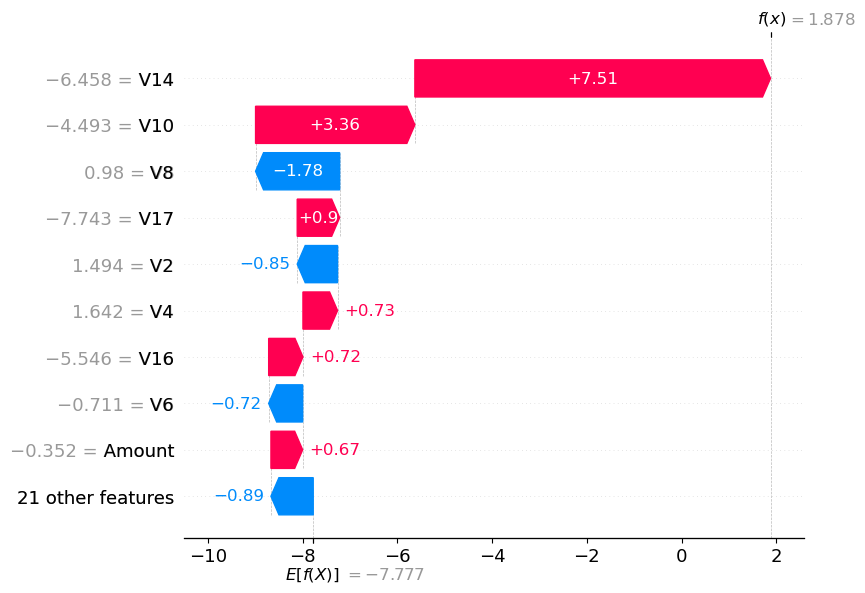

In [15]:
shap_explainer = shap.TreeExplainer(model)
sv_one = shap_explainer.shap_values(x.reshape(1, -1))[0]
shap_series = pd.Series(sv_one, index=feature_names)
print(shap_series.loc[shap_series.abs().sort_values(ascending=False).index].head(5))

shap.plots.waterfall(shap.Explanation(values=sv_one,
                                      base_values=shap_explainer.expected_value,
                                      data=x, feature_names=feature_names))

In [16]:
lime_explainer = LimeTabularExplainer(X_train_s, feature_names=feature_names,
                                      class_names=["normal", "fraud"],
                                      mode="classification", random_state=42)
exp = lime_explainer.explain_instance(x, model.predict_proba,
                                      num_features=len(feature_names),
                                      num_samples=1000, labels=(1,))
lime_series = pd.Series({feature_names[f]: w for f, w in exp.as_map()[1]})
print(lime_series.loc[lime_series.abs().sort_values(ascending=False).index].head(5))

V14    0.009735
V4     0.009346
V11    0.008232
V24    0.007799
V18    0.007734
dtype: float64


In [17]:
a = shap_series.abs()
b = lime_series.abs().reindex(a.index)
rho = spearmanr(a, b).correlation
top_shap = set(a.sort_values(ascending=False).head(5).index)
top_lime = set(b.sort_values(ascending=False).head(5).index)
print("Spearman:", round(rho, 3))
print("Top-5 overlap:", len(top_shap & top_lime), "of 5 ->", top_shap & top_lime)

Spearman: 0.12
Top-5 overlap: 1 of 5 -> {'V14'}


In [18]:
def lime_top(seed, discretize=True):
    le = LimeTabularExplainer(X_train_s, feature_names=feature_names,
                              class_names=["normal", "fraud"], mode="classification",
                              random_state=seed, discretize_continuous=discretize)
    e = le.explain_instance(x, model.predict_proba, num_features=len(feature_names),
                            num_samples=1000, labels=(1,))
    s = pd.Series({feature_names[f]: w for f, w in e.as_map()[1]})
    return s, e

# Test 1 and 2: same transaction, three different random seeds
for seed in [42, 7, 123]:
    s, e = lime_top(seed)
    print(seed, list(s.abs().sort_values(ascending=False).head(5).index),
          "| local fit R2 =", round(e.score, 3), "| LIME's local prediction =", round(float(e.local_pred[0]), 3))
print("Model's real P(fraud):", round(float(proba[i]), 3))

# Test 3: LIME without the 4-bin cutting
s_nd, e_nd = lime_top(42, discretize=False)
print("no bins:", list(s_nd.abs().sort_values(ascending=False).head(5).index),
      "| R2 =", round(e_nd.score, 3))

42 ['V14', 'V4', 'V11', 'V24', 'V18'] | local fit R2 = 0.155 | LIME's local prediction = 0.136
7 ['V25', 'V17', 'V14', 'V27', 'V12'] | local fit R2 = 0.158 | LIME's local prediction = 0.135
123 ['V4', 'V15', 'V10', 'Amount', 'V3'] | local fit R2 = 0.15 | LIME's local prediction = 0.13
Model's real P(fraud): 0.867
no bins: ['V17', 'V14', 'V16', 'V12', 'V18'] | R2 = 0.993


In [19]:
print("No-bins LIME local prediction:", round(float(e_nd.local_pred[0]), 3), "| model's real P(fraud):", round(float(proba[i]), 3))

No-bins LIME local prediction: 0.861 | model's real P(fraud): 0.867


In [20]:
# ---------- Part C: repeat over many transactions ----------
rng = np.random.RandomState(42)
fraud_pos  = np.where(y_test.values == 1)[0]
normal_pos = np.where(y_test.values == 0)[0]
idx = np.concatenate([rng.choice(fraud_pos, 30, replace=False),
                      rng.choice(normal_pos, 30, replace=False)])
X_eval = X_test_s[idx]
is_fraud = y_test.values[idx] == 1

shap_all = shap_explainer.shap_values(X_eval)          # SHAP for all 60 rows at once

le_bins = LimeTabularExplainer(X_train_s, feature_names=feature_names, class_names=["normal", "fraud"],
                               mode="classification", random_state=42, discretize_continuous=True)
le_raw  = LimeTabularExplainer(X_train_s, feature_names=feature_names, class_names=["normal", "fraud"],
                               mode="classification", random_state=42, discretize_continuous=False)

def lime_vec(explainer, row):
    e = explainer.explain_instance(row, model.predict_proba, num_features=len(feature_names),
                                   num_samples=1000, labels=(1,))
    v = np.zeros(len(feature_names))
    for f, w in e.as_map()[1]:
        v[f] = w
    return v, e.score

def agree(u, v, k=5):
    u, v = np.abs(u), np.abs(v)
    rho = spearmanr(u, v).correlation
    overlap = len(set(np.argsort(-u)[:k]) & set(np.argsort(-v)[:k]))
    return rho, overlap

rows = []
for n in range(len(idx)):
    vb, r2b = lime_vec(le_bins, X_eval[n])
    vr, r2r = lime_vec(le_raw, X_eval[n])
    rho_b, ov_b = agree(shap_all[n], vb)
    rho_r, ov_r = agree(shap_all[n], vr)
    rows.append(dict(is_fraud=is_fraud[n], rho_bins=rho_b, overlap_bins=ov_b, r2_bins=r2b,
                     rho_nobins=rho_r, overlap_nobins=ov_r, r2_nobins=r2r))
results = pd.DataFrame(rows)

print("A random ranking would share about", round(5 * 5 / len(feature_names), 1), "of the top 5 by pure chance\n")
print("Average over all", len(results), "transactions:")
print(results.drop(columns="is_fraud").mean().round(2), "\n")
print("Split by fraud / normal:")
results.groupby("is_fraud").mean().round(2)

A random ranking would share about 0.8 of the top 5 by pure chance

Average over all 60 transactions:
rho_bins          0.18
overlap_bins      1.55
r2_bins           0.10
rho_nobins        0.33
overlap_nobins    2.33
r2_nobins         0.28
dtype: float64 

Split by fraud / normal:


,rho_bins,overlap_bins,r2_bins,rho_nobins,overlap_nobins,r2_nobins
is_fraud,,,,,,
False,0.17,1.5,0.05,0.27,2.17,0.07
True,0.19,1.6,0.14,0.40,2.50,0.48


In [21]:
fr = results[results.is_fraud]
print("Share of fraud transactions with LIME fit R2 above 0.5:")
print("  default (bins):", round((fr.r2_bins > 0.5).mean(), 2))
print("  no bins       :", round((fr.r2_nobins > 0.5).mean(), 2))

Share of fraud transactions with LIME fit R2 above 0.5:
  default (bins): 0.0
  no bins       : 0.5


In [22]:
# ---------- Part D: does the imbalance fix change the explanation? ----------
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

def train_xgb(strategy, seed=42):
    Xr, yr = X_train_s, y_train
    spw = 1.0
    if strategy == "class_weight":
        spw = (y_train == 0).sum() / (y_train == 1).sum()      # fraud mistakes count this many times more
    if strategy == "smote":
        Xr, yr = SMOTE(random_state=seed).fit_resample(X_train_s, y_train)
    if strategy == "undersample":
        Xr, yr = RandomUnderSampler(random_state=seed).fit_resample(X_train_s, y_train)
    m = XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.1, subsample=0.8,
                      colsample_bytree=0.8, scale_pos_weight=spw, eval_metric="logloss",
                      random_state=seed, n_jobs=-1)
    m.fit(Xr, yr)
    return m

models = {s: train_xgb(s) for s in ["none", "class_weight", "smote", "undersample"]}
models["none_reseed"] = train_xgb("none", seed=43)      # same as "none", only the random seed differs = noise floor

perf = []
for name, m in models.items():
    p = m.predict_proba(X_test_s)[:, 1]
    perf.append(dict(model=name, roc_auc=roc_auc_score(y_test, p), pr_auc=average_precision_score(y_test, p)))
print(pd.DataFrame(perf).round(3).to_string(index=False))

fraud_rows = X_eval[is_fraud]                            # the 30 real frauds picked in Part C
shap_by = {name: shap.TreeExplainer(m).shap_values(fraud_rows) for name, m in models.items()}

def lime_matrix(m, rows_):
    ex = LimeTabularExplainer(X_train_s, feature_names=feature_names, class_names=["normal", "fraud"],
                              mode="classification", random_state=42, discretize_continuous=False)
    out = np.zeros((len(rows_), len(feature_names)))
    for n, r in enumerate(rows_):
        e = ex.explain_instance(r, m.predict_proba, num_features=len(feature_names),
                                num_samples=1000, labels=(1,))
        for f, w in e.as_map()[1]:
            out[n, f] = w
    return out
lime_by = {name: lime_matrix(m, fraud_rows) for name, m in models.items()}

print("\nTop-5 features by average |SHAP| over the 30 frauds:")
for name in models:
    g = np.abs(shap_by[name]).mean(0)
    print(f"  {name:<13}", [feature_names[i] for i in np.argsort(-g)[:5]])

def mean_agree(A, B, k=5):
    r = [agree(a, b, k) for a, b in zip(A, B)]
    return np.nanmean([x[0] for x in r]), np.mean([x[1] for x in r])

rows = []
for name in ["class_weight", "smote", "undersample", "none_reseed"]:
    s_rho, s_ov = mean_agree(shap_by["none"], shap_by[name])
    l_rho, l_ov = mean_agree(lime_by["none"], lime_by[name])
    rows.append(dict(vs_none=name, shap_rho=s_rho, shap_top5=s_ov, lime_rho=l_rho, lime_top5=l_ov))
print("\nHow much does the explanation change compared with the plain model? (1.0 / 5 = unchanged)")
shift = pd.DataFrame(rows).round(2)
shift

       model  roc_auc  pr_auc
        none    0.977   0.853
class_weight    0.984   0.863
       smote    0.979   0.845
 undersample    0.977   0.652
 none_reseed    0.975   0.871

Top-5 features by average |SHAP| over the 30 frauds:
  none          ['V14', 'V10', 'V4', 'V8', 'V16']
  class_weight  ['V14', 'V4', 'V10', 'V12', 'V17']
  smote         ['V14', 'V4', 'V17', 'V7', 'V10']
  undersample   ['V14', 'V4', 'V12', 'V10', 'V7']
  none_reseed   ['V14', 'V17', 'V4', 'V10', 'V12']

How much does the explanation change compared with the plain model? (1.0 / 5 = unchanged)


,vs_none,shap_rho,shap_top5,lime_rho,lime_top5
0,class_weight,0.60,3.10,0.86,4.37
1,smote,0.53,2.53,0.79,4.13
2,undersample,0.40,2.67,0.62,3.63
3,none_reseed,0.70,3.27,0.88,4.53


In [23]:
# ---------- Part E: repeat with several seeds (SHAP only, so it stays fast) ----------
seeds = [0, 1, 2, 3, 4]
out = []
for sd in seeds:
    base = train_xgb("none", seed=sd)
    base_shap = shap.TreeExplainer(base).shap_values(fraud_rows)
    for name in ["class_weight", "smote", "undersample"]:
        m = train_xgb(name, seed=sd)
        rho, top5 = mean_agree(base_shap, shap.TreeExplainer(m).shap_values(fraud_rows))
        out.append(dict(seed=sd, vs_none=name, shap_rho=rho, shap_top5=top5))
    m2 = train_xgb("none", seed=sd + 100)                  # noise floor: same strategy, different seed
    rho, top5 = mean_agree(base_shap, shap.TreeExplainer(m2).shap_values(fraud_rows))
    out.append(dict(seed=sd, vs_none="none_reseed", shap_rho=rho, shap_top5=top5))
    print("seed", sd, "done")
multi = pd.DataFrame(out)
multi.groupby("vs_none")[["shap_rho", "shap_top5"]].agg(["mean", "std"]).round(2)

seed 0 done
seed 1 done
seed 2 done
seed 3 done
seed 4 done


shap_rho       shap_top5      
                 mean   std      mean   std
vs_none                                    
class_weight     0.60  0.02      3.27  0.31
none_reseed      0.76  0.02      3.34  0.26
smote            0.55  0.02      3.05  0.25
undersample      0.47  0.09      3.03  0.37